# Demand Anomaly Detection & Inventory Intelligence
### End-to-End Supply Chain Analytics

**Business Goal:** Detect abnormal demand behaviour early — before it becomes a stockout or overstock event.

---
**Techniques:** Time-Series Feature Engineering · Z-Score · Isolation Forest · LOF · K-Means · PCA  
**Dataset:** UCI Online Retail (500k+ transactions → weekly product time series)

In [5]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
print('✅ All imports complete')

✅ All imports complete


## 1. Load & Reshape Data

Download UCI Online Retail → aggregate transactions into weekly product-level demand series.

In [7]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx'
print('Downloading UCI Online Retail dataset...')
#raw    = urllib.request.urlopen(url).read()
df_raw = pd.read_excel(url)

# Clean
df = df_raw.copy()
df = df.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df = df[df['StockCode'].astype(str).str.len() >= 5]
df = df[~df['StockCode'].isin(['POST','D','M','BANK CHARGES','PADS','DOT'])]
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Week'] = df['InvoiceDate'].dt.to_period('W').dt.start_time

print(f'Transactions: {len(df):,}')
print(f'Products:     {df["StockCode"].nunique():,}')
print(f'Date range:   {df["InvoiceDate"].min().date()} → {df["InvoiceDate"].max().date()}')

Transactions: 396,337
Products:     3,659
Date range:   2010-12-01 → 2011-12-09


In [3]:
# ── Weekly product-level demand series ──────────────────────────────────────
weekly = (
    df.groupby(['StockCode', 'Week'])['Quantity']
    .sum().reset_index()
    .rename(columns={'Quantity': 'units'})
)

# Keep products with >= 20 weeks of history
week_counts    = weekly.groupby('StockCode')['Week'].count()
valid_products = week_counts[week_counts >= 20].index
weekly         = weekly[weekly['StockCode'].isin(valid_products)].copy()

# Fill missing weeks with 0 (gaps = zero demand, not missing data)
all_weeks = pd.date_range(weekly['Week'].min(), weekly['Week'].max(), freq='W-MON')
products  = weekly['StockCode'].unique()
full_idx  = pd.MultiIndex.from_product([products, all_weeks], names=['StockCode','Week'])
weekly    = weekly.set_index(['StockCode','Week']).reindex(full_idx, fill_value=0).reset_index()

print(f'Products in time series: {len(products):,}')
print(f'Weeks in series:         {len(all_weeks)}')
print(f'Total rows:              {len(weekly):,}')

Products in time series: 1,948
Weeks in series:         54
Total rows:              105,192


## 2. Time-Series Feature Engineering

> Raw sales are noisy. Anomaly detection requires context — rolling statistics define what is *expected*.

In [4]:
weekly = weekly.sort_values(['StockCode', 'Week'])

def add_ts_features(group):
    g = group.copy()
    s = g['units']
    # Rolling statistics
    g['roll_mean_4']  = s.rolling(4,  min_periods=2).mean()
    g['roll_mean_8']  = s.rolling(8,  min_periods=4).mean()
    g['roll_std_4']   = s.rolling(4,  min_periods=2).std().fillna(0)
    g['roll_std_8']   = s.rolling(8,  min_periods=4).std().fillna(0)
    # Z-scores: deviations from rolling mean
    g['z_score_4']    = (s - g['roll_mean_4']) / (g['roll_std_4'] + 1e-9)
    g['z_score_8']    = (s - g['roll_mean_8']) / (g['roll_std_8'] + 1e-9)
    # Lag features
    g['lag_1']        = s.shift(1)
    g['lag_4']        = s.shift(4)
    # Week-over-week change
    g['pct_change']   = s.pct_change().replace([np.inf, -np.inf], 0).fillna(0)
    # Demand vs product long-run mean
    prod_mean         = s[s > 0].mean() if (s > 0).any() else 1
    g['demand_vs_mean'] = s / (prod_mean + 1e-9)
    return g

print('Engineering time-series features...')
weekly = weekly.groupby('StockCode', group_keys=False).apply(add_ts_features)
weekly = weekly.dropna(subset=['roll_mean_4', 'lag_1', 'lag_4'])
print(f'Feature rows: {len(weekly):,}')
weekly.head(8)

Engineering time-series features...
Feature rows: 97,400


,StockCode,Week,units,roll_mean_4,roll_mean_8,roll_std_4,roll_std_8,z_score_4,z_score_8,lag_1,lag_4,pct_change,demand_vs_mean
4,10120,2010-12-27,0,3.25,3.200000,6.5,5.630275,-0.5,-0.568356,0.0,3.0,0.0,0.000000
5,10120,2011-01-03,0,0.00,2.666667,0.0,5.202563,0.0,-0.512568,0.0,13.0,0.0,0.000000
6,10120,2011-01-10,0,0.00,2.285714,0.0,4.855042,0.0,-0.470792,0.0,0.0,0.0,0.000000
7,10120,2011-01-17,0,0.00,2.000000,0.0,4.566962,0.0,-0.437928,0.0,0.0,0.0,0.000000
8,10120,2011-01-24,0,0.00,1.625000,0.0,4.596194,0.0,-0.353553,0.0,0.0,0.0,0.000000
9,10120,2011-01-31,0,0.00,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000
10,10120,2011-02-07,0,0.00,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000
11,10120,2011-02-14,30,7.50,3.750000,15.0,10.606602,1.5,2.474874,0.0,0.0,0.0,3.108808


## 3. Anomaly Detection (3-Method Ensemble)

Three methods combined — an event is confirmed as an anomaly only when ≥2 methods agree.
This reduces false positives while maintaining sensitivity.

In [5]:
# ── Method 1: Z-Score (statistical) ─────────────────────────────────────────
Z_THRESHOLD = 2.5
weekly['anomaly_zscore'] = (np.abs(weekly['z_score_4']) > Z_THRESHOLD).astype(int)
print(f'Z-score anomalies: {weekly["anomaly_zscore"].sum():,} ({weekly["anomaly_zscore"].mean()*100:.1f}%)')

Z-score anomalies: 0 (0.0%)


In [6]:
# ── Method 2: Isolation Forest (ML-based) ───────────────────────────────────
IFOREST_FEATURES = ['units', 'z_score_4', 'z_score_8', 'pct_change', 'demand_vs_mean', 'lag_1', 'lag_4']

X_if    = weekly[IFOREST_FEATURES].fillna(0)
sc_if   = StandardScaler()
X_if_sc = sc_if.fit_transform(X_if)

iforest = IsolationForest(n_estimators=200, contamination=0.05, random_state=RANDOM_STATE, n_jobs=-1)
weekly['anomaly_iforest'] = (iforest.fit_predict(X_if_sc) == -1).astype(int)
weekly['anomaly_score']   = -iforest.score_samples(X_if_sc)  # higher = more anomalous

print(f'Isolation Forest anomalies: {weekly["anomaly_iforest"].sum():,} ({weekly["anomaly_iforest"].mean()*100:.1f}%)')

Isolation Forest anomalies: 4,870 (5.0%)


In [7]:
# ── Method 3: Local Outlier Factor (density-based) ──────────────────────────
# Run on a sample — LOF is O(n²) in memory
sample_size = min(20000, len(weekly))
sample_idx  = np.random.RandomState(RANDOM_STATE).choice(len(weekly), sample_size, replace=False)

lof        = LocalOutlierFactor(n_neighbors=20, contamination=0.05, n_jobs=-1)
lof_labels = lof.fit_predict(X_if_sc[sample_idx])

weekly['anomaly_lof'] = 0
weekly.iloc[sample_idx, weekly.columns.get_loc('anomaly_lof')] = (lof_labels == -1).astype(int)
print(f'LOF anomalies (sample): {(lof_labels==-1).sum():,} ({(lof_labels==-1).mean()*100:.1f}%)')

LOF anomalies (sample): 1,000 (5.0%)


In [8]:
# ── Ensemble: confirmed anomaly = ≥2 methods agree ──────────────────────────
weekly['anomaly_votes']    = weekly['anomaly_zscore'] + weekly['anomaly_iforest'] + weekly['anomaly_lof']
weekly['anomaly_ensemble'] = (weekly['anomaly_votes'] >= 2).astype(int)

print('=== ANOMALY DETECTION SUMMARY ===')
print(f'Z-Score:          {weekly["anomaly_zscore"].sum():5,} flags')
print(f'Isolation Forest: {weekly["anomaly_iforest"].sum():5,} flags')
print(f'LOF:              {weekly["anomaly_lof"].sum():5,} flags')
print(f'Ensemble (≥2):    {weekly["anomaly_ensemble"].sum():5,} flags ({weekly["anomaly_ensemble"].mean()*100:.1f}%)')

=== ANOMALY DETECTION SUMMARY ===
Z-Score:              0 flags
Isolation Forest: 4,870 flags
LOF:              1,000 flags
Ensemble (≥2):      120 flags (0.1%)


## 4. EDA & Anomaly Visualisation

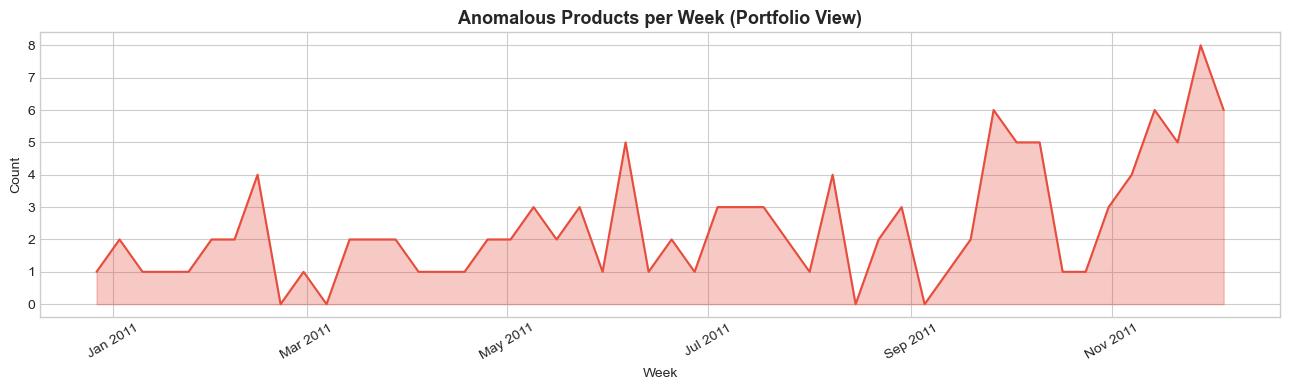

In [10]:
# ── Anomaly frequency by week ────────────────────────────────────────────────
weekly_anom = weekly.groupby('Week')['anomaly_ensemble'].sum().reset_index()

fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(weekly_anom['Week'], weekly_anom['anomaly_ensemble'], alpha=0.3, color='#e74c3c')
ax.plot(weekly_anom['Week'], weekly_anom['anomaly_ensemble'], color='#e74c3c', linewidth=1.5)
ax.set_title('Anomalous Products per Week (Portfolio View)', fontsize=13, fontweight='bold')
ax.set_xlabel('Week'); ax.set_ylabel('Count')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('..//reports/figures/ad_01_anomaly_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

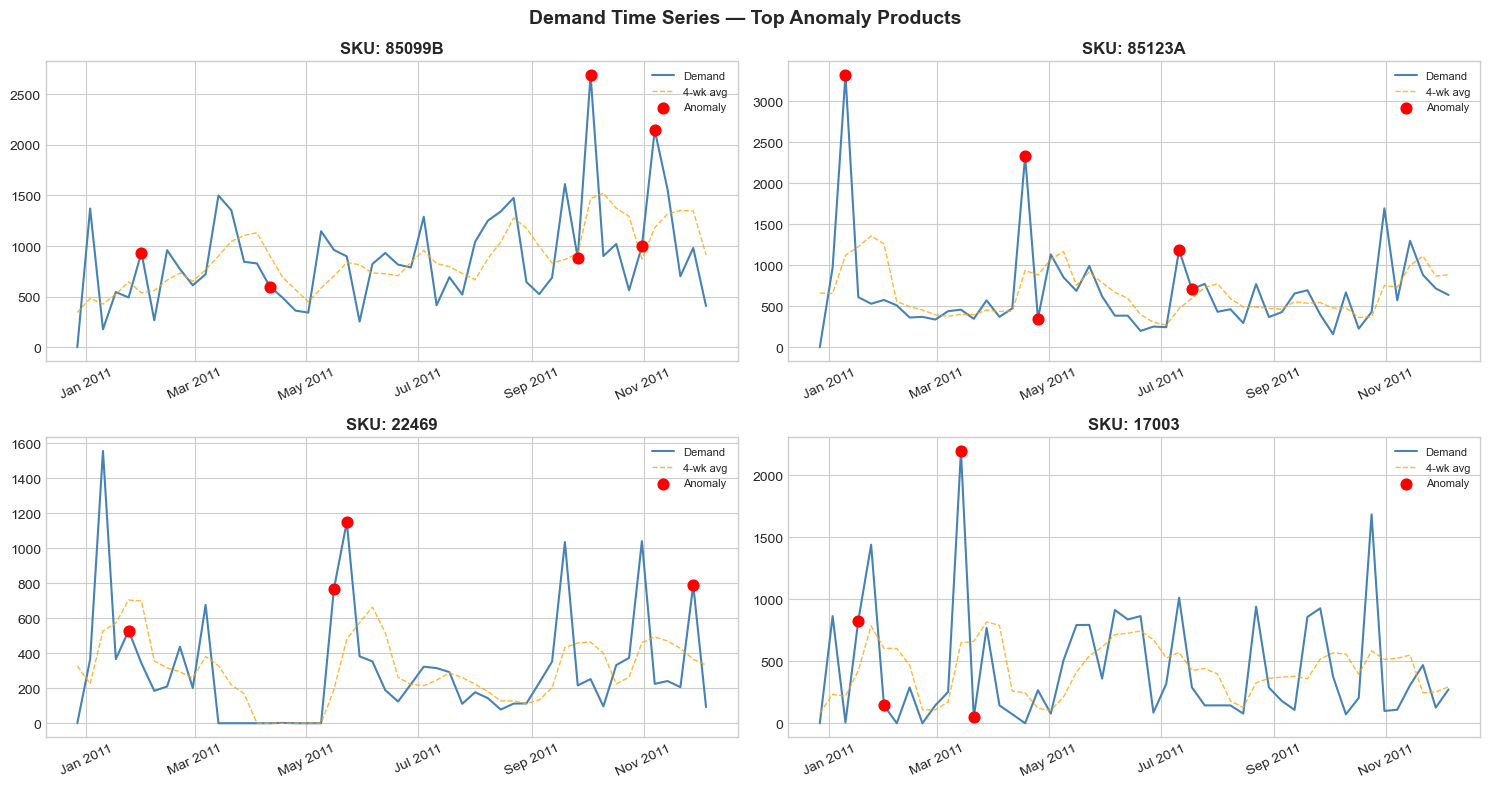

In [11]:
# ── Top 4 anomaly products — individual time series ─────────────────────────
top_skus = (
    weekly.groupby('StockCode')['anomaly_ensemble'].sum()
    .sort_values(ascending=False).head(4).index
)

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, sku in zip(axes.flatten(), top_skus):
    sub = weekly[weekly['StockCode'] == sku].sort_values('Week')
    ax.plot(sub['Week'], sub['units'], color='steelblue', linewidth=1.5, label='Demand')
    ax.plot(sub['Week'], sub['roll_mean_4'], color='orange', linestyle='--',
            linewidth=1, alpha=0.8, label='4-wk avg')
    anom = sub[sub['anomaly_ensemble'] == 1]
    ax.scatter(anom['Week'], anom['units'], color='red', s=60, zorder=5, label='Anomaly')
    ax.set_title(f'SKU: {sku}', fontweight='bold')
    ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=25)

plt.suptitle('Demand Time Series — Top Anomaly Products', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('..//reports/figures/ad_03_product_ts.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Product Segmentation by Anomaly Behaviour

In [12]:
# ── Product-level feature aggregation ───────────────────────────────────────
product_features = weekly.groupby('StockCode').agg(
    avg_demand        = ('units',             'mean'),
    demand_cv         = ('units',             lambda x: x.std()/(x.mean()+1e-9)),
    n_anomalies       = ('anomaly_ensemble',  'sum'),
    anomaly_rate      = ('anomaly_ensemble',  'mean'),
    avg_anomaly_score = ('anomaly_score',     'mean'),
    max_z_score       = ('z_score_4',         lambda x: x.abs().max()),
    avg_pct_change    = ('pct_change',        lambda x: x.abs().mean()),
    n_zero_weeks      = ('units',             lambda x: (x == 0).sum()),
    peak_to_mean      = ('units',             lambda x: x.max()/(x.mean()+1e-9)),
).reset_index()
product_features['demand_cv'] = product_features['demand_cv'].fillna(0)

print(f'Product feature matrix: {product_features.shape}')
product_features.head()

Product feature matrix: (1948, 10)


,StockCode,avg_demand,demand_cv,n_anomalies,anomaly_rate,avg_anomaly_score,max_z_score,avg_pct_change,n_zero_weeks,peak_to_mean
0,10120,3.54,2.313451,0,0.0,0.372056,1.50000,0.567091,32,10.734463
1,10125,21.66,1.712620,0,0.0,0.398593,1.50000,1.305509,19,9.095106
2,10133,45.22,1.531102,0,0.0,0.417586,1.49691,0.818654,21,5.417957
3,10135,31.44,1.455311,0,0.0,0.413710,1.50000,1.925284,9,6.679389
4,11001,23.74,2.327763,0,0.0,0.404163,1.50000,2.820821,15,16.175232


k=2 | Inertia: 13,086 | Silhouette: 0.6245
k=3 | Inertia: 9,473 | Silhouette: 0.3210
k=4 | Inertia: 7,943 | Silhouette: 0.3136
k=5 | Inertia: 6,653 | Silhouette: 0.3232
k=6 | Inertia: 5,751 | Silhouette: 0.3328
k=7 | Inertia: 5,196 | Silhouette: 0.3340
k=8 | Inertia: 4,684 | Silhouette: 0.3335


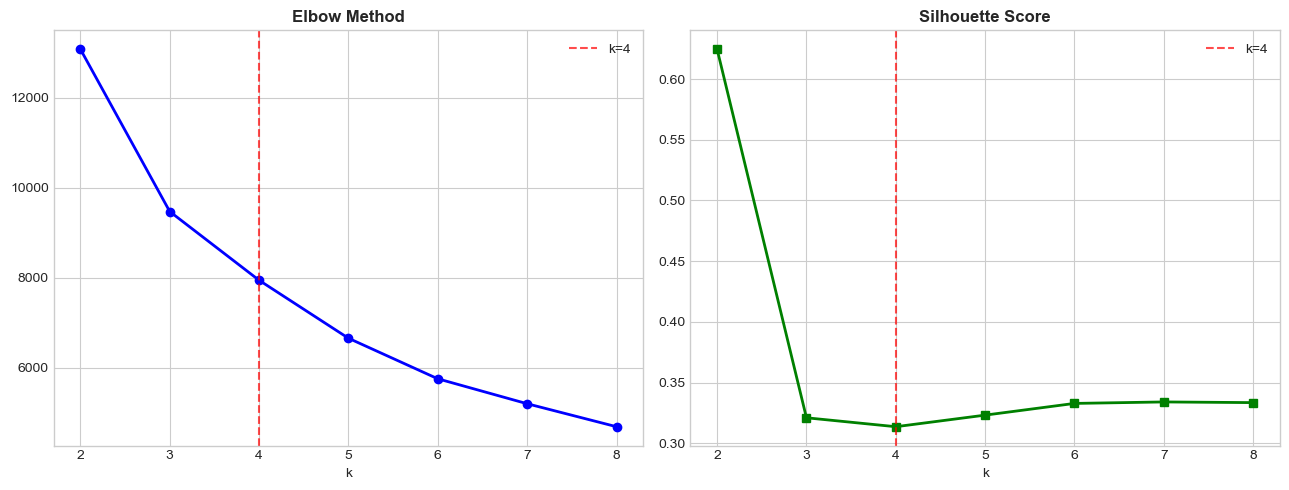

In [13]:
CLUSTER_FEATURES = [
    'avg_demand', 'demand_cv', 'n_anomalies',
    'anomaly_rate', 'avg_anomaly_score', 'max_z_score',
    'avg_pct_change', 'n_zero_weeks', 'peak_to_mean'
]

X_cl = product_features[CLUSTER_FEATURES].copy()
for col in X_cl.columns:
    X_cl[col] = X_cl[col].clip(upper=X_cl[col].quantile(0.99))

scaler_cl = StandardScaler()
X_cl_sc   = scaler_cl.fit_transform(X_cl)

# ── Find optimal k ────────────────────────────────────────────────────────────
inertia, sil = [], []
for k in range(2, 9):
    km  = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lbl = km.fit_predict(X_cl_sc)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_cl_sc, lbl))
    print(f'k={k} | Inertia: {km.inertia_:,.0f} | Silhouette: {sil[-1]:.4f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.plot(range(2,9), inertia, 'bo-', linewidth=2)
ax1.axvline(4, color='red', linestyle='--', alpha=0.7, label='k=4'); ax1.legend()
ax1.set_title('Elbow Method', fontweight='bold'); ax1.set_xlabel('k')
ax2.plot(range(2,9), sil, 'gs-', linewidth=2)
ax2.axvline(4, color='red', linestyle='--', alpha=0.7, label='k=4'); ax2.legend()
ax2.set_title('Silhouette Score', fontweight='bold'); ax2.set_xlabel('k')
plt.tight_layout()
plt.savefig('..//reports/figures/ad_04_optimal_k.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
K = 4
kmeans_cl = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
product_features['cluster'] = kmeans_cl.fit_predict(X_cl_sc)

final_sil = silhouette_score(X_cl_sc, product_features['cluster'])
print(f'Silhouette (k={K}): {final_sil:.4f}')
print(product_features['cluster'].value_counts().sort_index())

Silhouette (k=4): 0.3136
cluster
0    921
1    682
2     89
3    256
Name: count, dtype: int64


## 6. PCA Visualisation & Cluster Interpretation

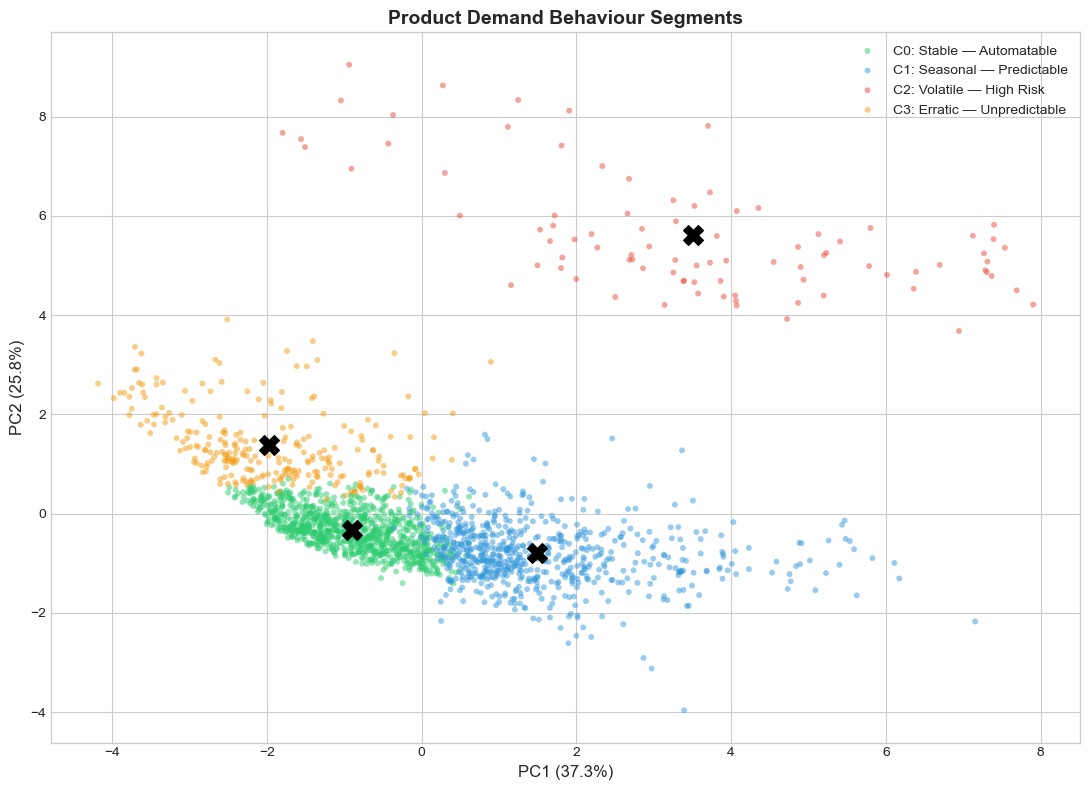

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cl_sc)
exp   = pca.explained_variance_ratio_ * 100

CLUSTER_NAMES = {
    0: 'Stable — Automatable',
    1: 'Seasonal — Predictable',
    2: 'Volatile — High Risk',
    3: 'Erratic — Unpredictable'
}
COLORS = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']

fig, ax = plt.subplots(figsize=(11, 8))
for i in range(K):
    m = product_features['cluster'] == i
    ax.scatter(X_pca[m, 0], X_pca[m, 1], c=COLORS[i],
               label=f'C{i}: {CLUSTER_NAMES[i]}', alpha=0.5, s=18, edgecolors='none')
cen_pca = pca.transform(kmeans_cl.cluster_centers_)
ax.scatter(cen_pca[:, 0], cen_pca[:, 1], c='black', marker='X', s=200, zorder=10)
ax.set_xlabel(f'PC1 ({exp[0]:.1f}%)', fontsize=12)
ax.set_ylabel(f'PC2 ({exp[1]:.1f}%)', fontsize=12)
ax.set_title('Product Demand Behaviour Segments', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('..//reports/figures/ad_05_pca_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

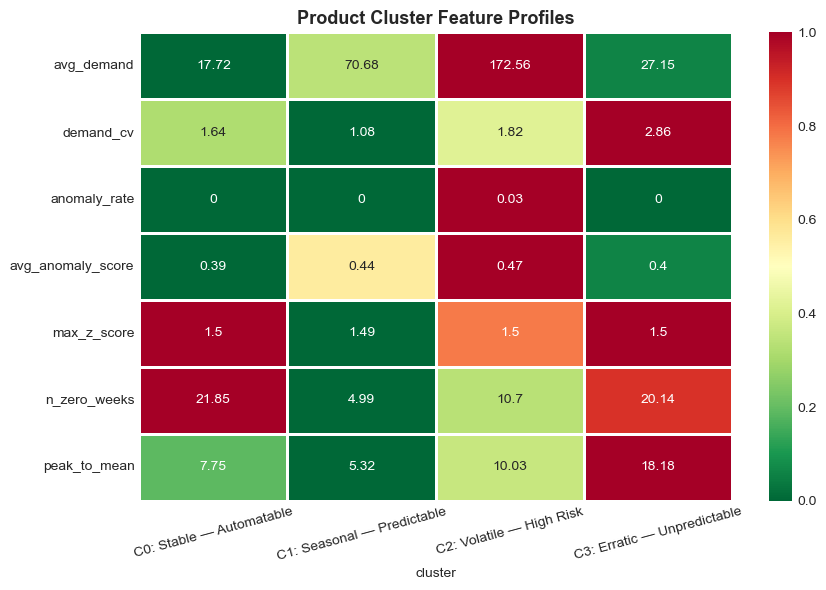

         avg_demand  demand_cv  anomaly_rate  avg_anomaly_score  max_z_score  \
cluster                                                                        
0            17.716      1.642         0.000              0.390        1.500   
1            70.680      1.080         0.000              0.437        1.491   
2           172.562      1.825         0.027              0.474        1.498   
3            27.152      2.856         0.000              0.395        1.500   

         n_zero_weeks  peak_to_mean  n_products  pct_portfolio  
cluster                                                         
0              21.851         7.751         921           47.3  
1               4.991         5.315         682           35.0  
2              10.697        10.027          89            4.6  
3              20.137        18.184         256           13.1  


In [16]:
SUMMARY_COLS = ['avg_demand', 'demand_cv', 'anomaly_rate', 'avg_anomaly_score',
                'max_z_score', 'n_zero_weeks', 'peak_to_mean']

cluster_summary = product_features.groupby('cluster')[SUMMARY_COLS].mean().round(3)
cluster_summary['n_products']    = product_features.groupby('cluster').size()
cluster_summary['pct_portfolio'] = (cluster_summary['n_products']/len(product_features)*100).round(1)

data_h = cluster_summary[SUMMARY_COLS].T
norm_h = (data_h - data_h.min(axis=1).values[:,None]) /          (data_h.max(axis=1) - data_h.min(axis=1) + 1e-9).values[:,None]

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(norm_h, annot=data_h.round(2), fmt='g', cmap='RdYlGn_r',
            ax=ax, linewidths=0.8, linecolor='white',
            xticklabels=[f'C{i}: {CLUSTER_NAMES[i]}' for i in range(K)])
ax.set_title('Product Cluster Feature Profiles', fontsize=13, fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('..//reports/figures/ad_06_cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

print(cluster_summary)

## 7. Cost Simulation: Ignore vs Detect

> Quantifies the financial value of anomaly detection — fill rate improvement and stockout cost reduction per segment.

In [17]:
class AnomalyCostSimulator:
    """
    Simulates inventory cost under two scenarios:
    - Ignore: order based on rolling average, miss anomaly spikes → stockouts
    - Detect: apply safety buffer on flagged weeks → fewer stockouts, slightly more holding cost
    """
    def __init__(self, unit_price=5.0, stockout_mult=2.0, holding_rate=0.20/52):
        self.unit_price    = unit_price
        self.stockout_mult = stockout_mult
        self.holding_rate  = holding_rate

    def simulate(self, actual, rolling_avg, anomaly_flags, safety_buffer=0.0):
        stock_ordered  = rolling_avg * (1 + safety_buffer * anomaly_flags)
        shortfall      = np.maximum(0, actual - stock_ordered)
        excess         = np.maximum(0, stock_ordered - actual)
        stockout_cost  = shortfall * self.unit_price * self.stockout_mult
        overstock_cost = excess   * self.unit_price * self.holding_rate
        total_cost     = stockout_cost + overstock_cost
        return {
            'total_cost':     total_cost.sum(),
            'stockout_cost':  stockout_cost.sum(),
            'overstock_cost': overstock_cost.sum(),
            'fill_rate':      1 - shortfall.sum() / (actual.sum() + 1e-9),
        }

print('✅ AnomalyCostSimulator ready')

✅ AnomalyCostSimulator ready


In [18]:
sim     = AnomalyCostSimulator()
results = []
price_map = df.groupby('StockCode')['UnitPrice'].median().to_dict()

for cluster_id in range(K):
    skus = product_features[product_features['cluster'] == cluster_id]['StockCode'].values
    for sku in skus[:min(50, len(skus))]:
        sub = weekly[weekly['StockCode'] == sku].sort_values('Week').dropna(
            subset=['roll_mean_4', 'anomaly_ensemble'])
        if len(sub) < 8: continue

        sim.unit_price = max(0.5, price_map.get(sku, 5.0))
        actual  = sub['units'].values
        avg_r   = sub['roll_mean_4'].values
        flags   = sub['anomaly_ensemble'].values

        ignore = sim.simulate(actual, avg_r, flags, safety_buffer=0.0)
        detect = sim.simulate(actual, avg_r, flags, safety_buffer=0.35)

        results.append({'StockCode': sku, 'cluster': cluster_id,
                        'cost_ignore': ignore['total_cost'], 'cost_detect': detect['total_cost'],
                        'fill_ignore': ignore['fill_rate'], 'fill_detect': detect['fill_rate']})

sim_df = pd.DataFrame(results)
sim_df['cost_saving'] = sim_df['cost_ignore'] - sim_df['cost_detect']
sim_df['saving_pct']  = sim_df['cost_saving'] / (sim_df['cost_ignore'] + 1e-9) * 100

print('=== SIMULATION RESULTS BY CLUSTER ===')
print(sim_df.groupby('cluster')[['cost_ignore','cost_detect','cost_saving','fill_ignore','fill_detect']].mean().round(2))

=== SIMULATION RESULTS BY CLUSTER ===
         cost_ignore  cost_detect  cost_saving  fill_ignore  fill_detect
cluster                                                                 
0             440.73       440.73         0.00         0.55         0.55
1            3659.11      3659.11         0.00         0.70         0.70
2            6461.19      6191.31       269.88         0.61         0.63
3            1658.59      1658.59         0.00         0.48         0.48


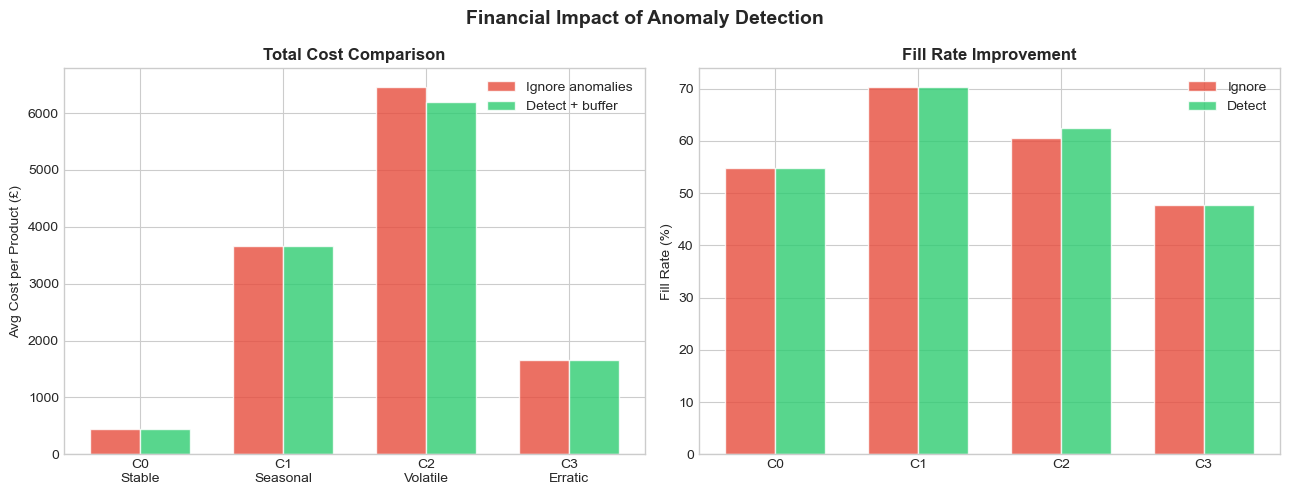

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cluster_costs = sim_df.groupby('cluster')[['cost_ignore','cost_detect']].mean()
x, w = np.arange(K), 0.35

axes[0].bar(x-w/2, cluster_costs['cost_ignore'], width=w, label='Ignore anomalies',
            color='#e74c3c', alpha=0.8, edgecolor='white')
axes[0].bar(x+w/2, cluster_costs['cost_detect'], width=w, label='Detect + buffer',
            color='#2ecc71', alpha=0.8, edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'C{i}\n{CLUSTER_NAMES[i].split(" — ")[0]}' for i in range(K)])
axes[0].set_ylabel('Avg Cost per Product (£)'); axes[0].set_title('Total Cost Comparison', fontweight='bold')
axes[0].legend()

fill_comp = sim_df.groupby('cluster')[['fill_ignore','fill_detect']].mean()
axes[1].bar(x-w/2, fill_comp['fill_ignore']*100, width=w, label='Ignore',
            color='#e74c3c', alpha=0.8, edgecolor='white')
axes[1].bar(x+w/2, fill_comp['fill_detect']*100, width=w, label='Detect',
            color='#2ecc71', alpha=0.8, edgecolor='white')
axes[1].set_xticks(x); axes[1].set_xticklabels([f'C{i}' for i in range(K)])
axes[1].set_ylabel('Fill Rate (%)'); axes[1].set_title('Fill Rate Improvement', fontweight='bold')
axes[1].legend()

plt.suptitle('Financial Impact of Anomaly Detection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('..//reports/figures/ad_08_cost_simulation.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Business Recommendations

In [20]:
STRATEGIES = {
    0: {'label': '🟢 Stable — Automatable',
        'profile': 'Low anomaly rate · Low CV · Consistent demand · Few zero-weeks',
        'inventory': 'Automate EOQ replenishment. No manual review needed.',
        'detection': 'Z-score monitoring only. Alert at |z| > 3.',
        'kpi': '99%+ service level | Zero manual reorders'},
    1: {'label': '🔵 Seasonal — Predictable',
        'profile': 'Recurring spikes · High peak-to-mean · Moderate anomaly rate',
        'inventory': 'Pre-build safety stock 2–3 weeks before known peaks.',
        'detection': 'Isolation Forest to separate true anomalies from seasonal peaks.',
        'kpi': 'Reduce seasonal stockouts 40% | Pre-build cost < 10% revenue'},
    2: {'label': '🔴 Volatile — High Risk',
        'profile': 'High anomaly rate · High CV · Large z-scores · Unpredictable spikes',
        'inventory': 'Increase safety stock 30–50%. Trigger emergency reorder on anomaly flag.',
        'detection': 'Full ensemble required. Weekly human review.',
        'kpi': 'Reduce stockout cost > 25% | Bi-weekly review cadence'},
    3: {'label': '🟡 Erratic — Unpredictable',
        'profile': 'High zero-weeks · No clear pattern · Intermittent demand',
        'inventory': 'Minimum viable stock. Make-to-order where feasible.',
        'detection': 'LOF best for sparse/intermittent demand.',
        'kpi': 'Minimise dead stock | Quarterly SKU rationalisation review'},
}

print('=== INVENTORY STRATEGY BY DEMAND BEHAVIOUR SEGMENT ===\n')
for cid, s in STRATEGIES.items():
    n  = (product_features['cluster'] == cid).sum()
    ar = product_features[product_features['cluster'] == cid]['anomaly_rate'].mean() * 100
    print(f"{s['label']} ({n:,} products | Anomaly rate: {ar:.1f}%)")
    print(f"  Profile   : {s['profile']}")
    print(f"  Inventory : {s['inventory']}")
    print(f"  Detection : {s['detection']}")
    print(f"  KPI       : {s['kpi']}")
    print()

=== INVENTORY STRATEGY BY DEMAND BEHAVIOUR SEGMENT ===

🟢 Stable — Automatable (921 products | Anomaly rate: 0.0%)
  Profile   : Low anomaly rate · Low CV · Consistent demand · Few zero-weeks
  Inventory : Automate EOQ replenishment. No manual review needed.
  Detection : Z-score monitoring only. Alert at |z| > 3.
  KPI       : 99%+ service level | Zero manual reorders

🔵 Seasonal — Predictable (682 products | Anomaly rate: 0.0%)
  Profile   : Recurring spikes · High peak-to-mean · Moderate anomaly rate
  Inventory : Pre-build safety stock 2–3 weeks before known peaks.
  Detection : Isolation Forest to separate true anomalies from seasonal peaks.
  KPI       : Reduce seasonal stockouts 40% | Pre-build cost < 10% revenue

🔴 Volatile — High Risk (89 products | Anomaly rate: 2.7%)
  Profile   : High anomaly rate · High CV · Large z-scores · Unpredictable spikes
  Inventory : Increase safety stock 30–50%. Trigger emergency reorder on anomaly flag.
  Detection : Full ensemble required. Week

## 9. Export

In [21]:
import joblib

weekly.to_csv('..//data/processed/demand_anomaly_weekly.csv', index=False)
product_features.to_csv('..//data/processed/product_clusters.csv', index=False)
sim_df.to_csv('..//data/processed/simulation_results.csv', index=False)
cluster_summary.to_csv('..//data/processed/cluster_summary.csv')

joblib.dump(iforest,    '..//models/isolation_forest.pkl')
joblib.dump(kmeans_cl,  '..//models/kmeans_products.pkl')
joblib.dump(scaler_cl,  '..//models/scaler_products.pkl')

print('✅ All outputs saved.')
print('  → ..//data/processed/demand_anomaly_weekly.csv')
print('  → ..//data/processed/product_clusters.csv')
print('  → ..//models/isolation_forest.pkl')

✅ All outputs saved.
  → ..//data/processed/demand_anomaly_weekly.csv
  → ..//data/processed/product_clusters.csv
  → ..//models/isolation_forest.pkl
